# Can RoBERTa Judge If Two Hate Speech Rationales Mean the Same Thing? Methods and Limits

**EE-559 Deep Learning - Group 26**
Veronika Wannack, Flavia Wallenhorst, Dimitri Pelgrin (EPFL)

---

In this notebook, we run you through our code and comment some results from the report. 

## What we are solving

Evaluating hate speech detection models is very expensive and complicated, because hate speech is subjective, and there is no universally accepted ground truth. This makes moderation realiability hard to measure by language models. Our goal is to build a framework to evaluate the alignment between human and LLM-speech rationales. To do this at scale, we build a lightweight alternative to "LLM-as-a-Judge": we fine-tune a 125M-parameter RoBERTa* judge to cheaply classify whether two hate speech rationales are semantically equivalent, or not. 

We found that the central issue revolves around shortcut learning, which is where our small judge memorises stylistic patterns or lexical information instead of understanding semantic meaning. In this notebook, we started from generating synthetic data and training RoBERTa on this data, to discover that we get near-perfect validation scores, but have catastrophic failure on unseen data. We then seek to analyse what is happening, and how we can mitigate this. 


## What we did (and what this notebook shows)

1. Synthetic Data Generation (Part I, Sections 0-5). We use Qwen2.5-3B-Instruct to generate ~52k labelled rationale pairs (equivalent paraphrases vs. non-equivalent perturbations) via zero-shot then few-shot prompting, and validate them with cosine similarity and an LLM flip-rate audit.

2. Initial RoBERTa Fine-Tuning (Sections 6-7). We fine-tune RoBERTa-base as asentence-pair classifier on the synthetic pairs, using a domain-out-of-distribution split. In-distribution F1 looks excellent (0.968).

3. Diagnosing the Failures with Mechanistic Interpretability (Sections 8-9). The judge collapses to ~55% (coin-flip) onrationales written by a different author. Mechanistic interpretability, with layer-wise probes and directional ablation, localises a redundantly-encoded stylistic shortcut in the deep layers.

4. The Fix: Generator Diversity (Sections 10-11). We regenerate ~1,000 pairs from five instruction-tuned LLMs (Claude Haiku 4.5, GPT-4o-mini, Qwen2.5-72B, Llama 3.1 8B, DeepSeek V3) and re-train. This removes the collapse, reaching 72-95% on human and cross-LLM data, and beats raw data scale.

Our takeaways: training small encoders on single generator synth data gives semantic illusions, that is, the validation scores are great, but hide the shortcuts taken through stylistic tweaks, that break on unfamiliar writing styles. The shortcut is spread across many directions and cannot be ablated away at inference, as we found through mechanistic interpretability. So, having better data, in this case ~1,000 cross-generator pairs, our 125M model is capable of performing in similar ways to a frontier LLM's judge at just a little of the cost. 

## How to read this notebook 

Part I (data generation) is fully runnable given a GPU and the source CSV. 

Part II Section 6 (fine-tuning the judge) is runnable here given a GPU; it trains end to end on the full set in about ten to fifteen minutes, or in seconds with `MAX_SAMPLES` set. The later analysis sections are short excerpts of the cluster scripts in `code/`, with their numbers read back from the committed artifacts in `results/`. 

The appendix rebuilds the tables and figure from those stored artifacts on a clean clone. 

# Synthetic Data Generation for Rationale Equivalence

This part documents the full pipeline for generating synthetic training data used to train a **rationale equivalence classifier**.

The classifier's task is to determine whether two natural-language rationales convey the **same meaning** (equivalent) or a **different meaning** (unequivalent). This kind of labelled pair data is expensive to collect from humans at scale, so it is generated synthetically using a large language model.

---

## What problem does this solve?

The downstream model (a fine-tuned RoBERTa classifier) needs to learn to distinguish between:
- **Equivalent pairs**: two texts that express the same underlying claim or verdict.
- **Unequivalent pairs**: two texts where the meaning has changed

Rather than hand-labelling thousands of pairs, we use a capable LLM (Qwen 2.5) to produce the synthetic counterpart for each original rationale. The label (`equivalent` or `unequivalent`) is controlled deterministically by which prompt we give the model.

---

## Two iterations of the pipeline

| Version | Approach | Model | Key idea |
|---------|----------|-------|----------|
| **v1: Original** | Zero-shot | Qwen 2.5-3B-Instruct-GPTQ-Int4 | Static system prompt, no examples |
| **v2: Improved** | Few-shot | Qwen 2.5-3B-Instruct-GPTQ-Int4 | Dynamic prompts seeded with manually labelled human examples |

Both versions use the same model. The difference is entirely in the prompting strategy.

---
## 0. Imports and dependencies

In [1]:
import argparse
import random

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# vLLM is a high-throughput inference engine for large language models.
# It handles batching, KV-cache management, and GPU memory allocation
# efficiently, which makes it practical to run generation over thousands
# of rows in a reasonable amount of time.
from vllm import LLM, SamplingParams

---
## 1. Source dataset

The input is a CSV file derived from the **HateCOT** dataset a collection of social media posts annotated for hate speech, each accompanied by a natural-language explanation (rationale) of why the post does or does not constitute hate speech.

Each row contains:
- `post`: the original social media text
- `explanation`: the rationale for the hate speech classification
- `label`: the hate speech verdict (`hate` / `not hate`)
- `domain`: which sub-dataset the example comes from (used later for domain-OOD evaluation)

The `explanation` column is the field we will be rewriting synthetically.

In [2]:
# Path to the curated source file. Change this to point to your local copy.
INPUT_PATH = "data/hatecot_final_D3.csv"

# The column whose text we will rewrite. Every other column is preserved
# unchanged in the output, so the synthetic file remains aligned with the
# original metadata (post, label, domain, etc.).
TARGET_COLUMN = "explanation"

df = pd.read_csv(INPUT_PATH)

# Drop rows where the target column is empty, the model has nothing to
# rewrite and would produce degenerate outputs.
df = df[df[TARGET_COLUMN].notna()]
df = df[df[TARGET_COLUMN].astype(str).str.strip() != ""]

print(f"Total usable rows: {len(df)}")
print(df[["domain", "label"]].value_counts().sort_index())

Total usable rows: 52137
domain      label                     
anatomy     Hateful                       2925
            Neutral                       2493
cad         Affiliation Directed Abuse    1032
            Identity Directed Abuse       1245
            Neutral                       3591
            Person Directed Abuse          849
dynahate    Animosity                     1326
            Dehumanization                 513
            Derogation                    1293
            Not Hate                      4077
gab         Hate                          3219
            Not Hate                      1815
measure     Hate Speech                   3609
            Not Hate Speech               3663
socialbias  Not Offensive                 3006
            Offensive                     3027
toraman     Hate                          1767
            Normal                        3663
            Offensive                     1785
toxigen     Benign                        3

### Sampling

Full-dataset generation is run on a GPU cluster. For development and inspection we sample a small subset.

In [3]:
# Number of rows to process. Set to -1 to run the full dataset.
N_SAMPLES = 50
SEED = 42

if N_SAMPLES > 0:
    sample = df.sample(n=min(N_SAMPLES, len(df)), random_state=SEED).reset_index(drop=True)
else:
    sample = df.reset_index(drop=True)

print(f"Working with {len(sample)} rows.")
sample.head(3)

Working with 50 rows.


,id,explanation,domain,label,post,target,uid
0,1343468911942135809,The post does not contain any language that ta...,toraman,Normal,The incident itself could have been a watershe...,NaN,toraman_1343468911942135809
1,24394,The post should be classified as Hateful becau...,anatomy,Hateful,I hate these fake ass interviews.,NaN,anatomy_24394
2,5276,The post targets both men and women by discuss...,measure,Not Hate Speech,Women should tell the truth. Like the sex got ...,"Men , Women",measure_5276


### Label assignment

Each row in the output will carry one of two labels:
- **`equivalent`**: the synthetic text should preserve the meaning of the original.
- **`unequivalent`**: the synthetic text should change the meaning in a detectable way.

Labels are assigned by simple alternation (even index → equivalent, odd index → unequivalent). This guarantees a **balanced 50 / 50 class split** regardless of dataset size, which is important for training a binary classifier without needing to re-weight classes.

In [4]:
# Alternating assignment produces an exactly balanced dataset.
labels = [
    "equivalent" if i % 2 == 0 else "unequivalent"
    for i in range(len(sample))
]

print(f"equivalent:   {labels.count('equivalent')}")
print(f"unequivalent: {labels.count('unequivalent')}")

equivalent:   25
unequivalent: 25


---
## 2. Model setup

The model is loaded **once** and reused across both generation pipelines. Both pipelines use identical inference settings, only the prompts differ.

**Model:** `Qwen/Qwen2.5-3B-Instruct-GPTQ-Int4` (4-bit GPTQ, ~4 GB VRAM)

In [5]:
# dtype=float16 is required on NVIDIA V100 GPUs, which do not support
# bfloat16 hardware instructions.
llm = LLM(
    model="Qwen/Qwen2.5-3B-Instruct-GPTQ-Int4",
    tensor_parallel_size=1,
    max_model_len=2048,
    gpu_memory_utilization=0.85,
    dtype="float16",
    quantization="gptq",
    trust_remote_code=True,
)
tokenizer = llm.get_tokenizer()

# Shared sampling parameters used by both pipelines.
sampling_params = SamplingParams(temperature=0.7, top_p=0.9, max_tokens=512)

INFO 06-05 13:44:51 [utils.py:233] non-default args: {'trust_remote_code': True, 'dtype': 'float16', 'max_model_len': 2048, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'quantization': 'gptq', 'model': 'Qwen/Qwen2.5-3B-Instruct-GPTQ-Int4'}
INFO 06-05 13:44:52 [model.py:549] Resolved architecture: Qwen2ForCausalLM
INFO 06-05 13:44:52 [model.py:1678] Using max model len 2048
INFO 06-05 13:44:56 [scheduler.py:238] Chunked prefill is enabled with max_num_batched_tokens=8192.
WARNING 06-05 13:44:56 [gptq.py:99] Currently, the 4-bit gptq_gemm kernel for GPTQ is buggy. Please switch to gptq_marlin.
INFO 06-05 13:44:57 [vllm.py:790] Asynchronous scheduling is enabled.
(EngineCore pid=3192) INFO 06-05 13:44:58 [core.py:105] Initializing a V1 LLM engine (v0.19.0) with config: model='Qwen/Qwen2.5-3B-Instruct-GPTQ-Int4', speculative_config=None, tokenizer='Qwen/Qwen2.5-3B-Instruct-GPTQ-Int4', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trus

(EngineCore pid=3192) <frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
(EngineCore pid=3192) <frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.nvrtc module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.nvrtc module instead.


(EngineCore pid=3192) INFO 06-05 13:45:02 [weight_utils.py:625] No model.safetensors.index.json found in remote.
(EngineCore pid=3192) INFO 06-05 13:45:02 [weight_utils.py:848] Prefetching checkpoint files into page cache started (in background)


Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]


(EngineCore pid=3192) INFO 06-05 13:45:03 [weight_utils.py:825] Prefetching checkpoint files: 10% (1/1)
(EngineCore pid=3192) INFO 06-05 13:45:03 [weight_utils.py:843] Prefetching checkpoint files into page cache finished in 0.51s
(EngineCore pid=3192) INFO 06-05 13:45:03 [default_loader.py:384] Loading weights took 0.71 seconds
(EngineCore pid=3192) INFO 06-05 13:45:04 [gpu_model_runner.py:4820] Model loading took 1.95 GiB memory and 3.058032 seconds
(EngineCore pid=3192) INFO 06-05 13:45:12 [backends.py:1051] Using cache directory: /home/.cache/vllm/torch_compile_cache/1e2d2c7512/rank_0_0/backbone for vLLM's torch.compile
(EngineCore pid=3192) INFO 06-05 13:45:12 [backends.py:1111] Dynamo bytecode transform time: 7.68 s
(EngineCore pid=3192) INFO 06-05 13:45:18 [backends.py:285] Directly load the compiled graph(s) for compile range (1, 8192) from the cache, took 4.473 s
(EngineCore pid=3192) INFO 06-05 13:45:18 [decorators.py:303] Directly load AOT compilation from path /home/.cache/

Capturing CUDA graphs (mixed prefill-decode, PIECEWISE): 100%|██████████| 51/51 [00:04<00:00, 11.52it/s]
Capturing CUDA graphs (decode, FULL): 100%|██████████| 35/35 [00:02<00:00, 12.58it/s]


(EngineCore pid=3192) INFO 06-05 13:45:31 [gpu_model_runner.py:6046] Graph capturing finished in 8 secs, took 0.72 GiB
(EngineCore pid=3192) INFO 06-05 13:45:31 [gpu_worker.py:597] CUDA graph pool memory: 0.72 GiB (actual), 0.74 GiB (estimated), difference: 0.03 GiB (3.8%).
(EngineCore pid=3192) INFO 06-05 13:45:31 [core.py:283] init engine (profile, create kv cache, warmup model) took 26.81 seconds


---
## 2. Pipeline v1, Zero-Shot Reformulation

The first version of the pipeline instructs the model through **system prompts alone**, with no demonstrations. It rewrites hate speech rationales in two modes:

- **Equivalent** prompt: produce an exact paraphrase that preserves every claim, entity, and verdict.
- **Unequivalent** prompt: produce a rewrite where the core assertion is clearly different, typically by flipping a verdict, swapping an entity, or inverting a sentiment.

**Model:** `Qwen/Qwen2.5-3B-Instruct` (unquantized, ~6 GB VRAM)

In [6]:
# --- EQUIVALENT system prompt ---
# The key constraints are: preserve meaning, tone, named entities, numbers,
# and intent. The instruction to output ONLY the reformulated sentence prevents
# the model from adding preamble like "Sure, here is the paraphrase:" which
# would contaminate the output.
SYSTEM_PROMPT_EQUIVALENT = (
    "You are a precise paraphrasing assistant. Rewrite the user's sentence in "
    "different words while preserving the exact meaning, tone, named entities, "
    "numbers, and intent. Do not add, omit, or infer information. Output ONLY "
    "the reformulated sentence, with no preamble, no quotes, no commentary."
)

# --- UNEQUIVALENT system prompt ---
# The model is given a menu of legal transformations rather than a free brief.
# This specificity is necessary: without it, the model tends to produce
# near-paraphrases that are technically different but not detectably so , 
# the resulting pairs would be mislabelled. The concrete example at the end
# anchors the model's behaviour in the zero-shot setting.
SYSTEM_PROMPT_UNEQUIVALENT = (
    "You are a sentence-rewriting assistant. Your job is to produce a sentence "
    "whose MEANING is clearly DIFFERENT from the original. The output must NOT "
    "be a paraphrase, a summary, or a shortened version of the input. Keep the "
    "topic, style, and approximate length similar, but apply at least ONE of "
    "the following transformations so the assertion changes:\n"
    "  - flip a verdict, claim, or negation (e.g. 'qualifies' -> 'does not "
    "qualify', 'is hate speech' -> 'is not hate speech', 'yes' -> 'no')\n"
    "  - swap a key entity, target group, person, or category for a different "
    "one\n"
    "  - invert the sentiment or stance (positive <-> negative, supports <-> "
    "opposes)\n"
    "  - change a key fact, number, or attribute\n"
    "Example:\n"
    "  Original: The post does not direct abuse at any identity and is a "
    "neutral statement.\n"
    "  Rewritten: The post directs abuse at a specific identity and is a "
    "hateful statement.\n"
    "A reader comparing the two sentences must immediately see they assert "
    "different things. Output ONLY the rewritten sentence, with no preamble, "
    "no quotes, no commentary."
)

In [7]:
def build_prompts(tokenizer, sentences: list[str], system_prompts: list[str]) -> list[str]:
    """
    Convert raw (sentence, system_prompt) pairs into the full prompt strings
    that vLLM will feed to the model.

    apply_chat_template inserts the model-specific special tokens
    (e.g. <|im_start|>, <|im_end|> for Qwen) and structures the
    system / user turns in the format the model was instruction-tuned on.
    Skipping this step would cause the model to ignore the system prompt
    or produce garbled output.
    """
    prompts = []
    for sentence, system in zip(sentences, system_prompts):
        messages = [
            {"role": "system", "content": system},
            {"role": "user",   "content": str(sentence)},
        ]
        prompts.append(
            tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True,  # appends the assistant turn opener
            )
        )
    return prompts

In [8]:
system_prompts_v1 = [
    SYSTEM_PROMPT_EQUIVALENT if label == "equivalent" else SYSTEM_PROMPT_UNEQUIVALENT
    for label in labels
]

originals_v1 = sample[TARGET_COLUMN].astype(str).tolist()
prompts_v1   = build_prompts(tokenizer, originals_v1, system_prompts_v1)

outputs_v1   = llm.generate(prompts_v1, sampling_params, use_tqdm=True)
synthetic_v1 = [output.outputs[0].text.strip() for output in outputs_v1]

Rendering prompts:   0%|          | 0/50 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/50 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

In [9]:
# Build the output dataframe by copying all original columns, then appending
# the two new columns. Keeping every original column is important so that
# downstream code (e.g. the domain-OOD split in judge_finetune) can still
# access fields like `domain` and `post`.
output_v1 = sample.copy()
output_v1["synthetic"] = synthetic_v1
output_v1["meaning"]   = labels

output_v1.to_csv("reformulated_v1.csv", index=False)
print(f"Saved {len(output_v1)} rows to reformulated_v1.csv")

# Quick sanity check: inspect a few pairs side by side.
output_v1[[TARGET_COLUMN, "synthetic", "meaning"]].head(6)

Saved 50 rows to reformulated_v1.csv


,explanation,synthetic,meaning
0,The post does not contain any language that ta...,The post does not include any language that di...,equivalent
1,The post should be classified as Hateful becau...,The post should be classified as neutral becau...,unequivalent
2,The post targets both men and women by discuss...,The post addresses men and women through discu...,equivalent
3,"The post ""No ragrats"" does not fall into any o...","The post ""No ragrats"" directs abuse towards a ...",unequivalent
4,This post does not contain any abusive speech ...,This posting lacks any abusive language direct...,equivalent
5,The post targets women by demeaning and object...,"The post, however, celebrates women by highlig...",unequivalent


---
## 3. Pipeline v2, Few-Shot with Human Examples

The zero-shot pipeline produces grammatically correct rewrites, but they can feel mechanical and easy to distinguish from human-written text purely by style. For the classifier to generalise to real annotator comments, the training data should **resemble the distribution of human writing**.

Pipeline v2 addresses this by:
1. Shifting the task from *rewriting a rationale* to *writing a first-person human annotator comment*.
2. Seeding each system prompt with **3 randomly sampled examples** drawn from a small manually-labelled set of real human comments.

This few-shot approach nudges the model toward the informal, opinionated register that actual annotators use, rather than the neutral register of a paraphrase tool.

**Model:** `Qwen/Qwen2.5-3B-Instruct-GPTQ-Int4`: same model as v1.

> The 7B model weights occupy ~7.5 GB, leaving no headroom for the KV cache on a 9.3 GB GPU. The key contribution of v2 is the **prompting strategy**, not the model size, so reusing the 3B model is the right trade-off here.

In [10]:
def load_fewshot_examples(manual_labels_path: str) -> dict:
    """
    Load the manually annotated CSV and split examples by label.

    The file has a header row followed by an additional descriptive row
    (skiprows=1 skips that second row so pandas reads only real data).
    Returns a dict with keys 'equivalent' and 'unequivalent', each holding
    a list of {post, human_comment} records used as few-shot demonstrations.
    """
    df = pd.read_csv(manual_labels_path, skiprows=1, header=0)

    # Normalise column names to the four fields we care about.
    df.columns = ["post", "explanation", "human_comment", "label"] + list(df.columns[4:])
    df = df[["post", "human_comment", "label"]].dropna(
        subset=["post", "human_comment", "label"]
    )

    # Normalise the label strings so capitalisation differences do not cause
    # examples to be silently dropped.
    df["label"] = df["label"].str.strip().str.lower()

    return {
        "equivalent":   df[df["label"] == "equivalent"][["post", "human_comment"]].to_dict("records"),
        "unequivalent": df[df["label"] == "unequivalent"][["post", "human_comment"]].to_dict("records"),
    }


fewshot = load_fewshot_examples("data/manual_labelling.csv")

print(f"Few-shot pool, equivalent:   {len(fewshot['equivalent'])} examples")
print(f"Few-shot pool, unequivalent: {len(fewshot['unequivalent'])} examples")

Few-shot pool, equivalent:   13 examples
Few-shot pool, unequivalent: 7 examples


In [11]:
def _format_shots(examples: list[dict], n: int, seed: int) -> str:
    """
    Randomly sample n examples and format them as a numbered list
    that will be embedded directly in the system prompt.

    A fresh seed per row ensures that different rows see different
    subsets of the example pool, which reduces prompt repetition and
    makes the model less likely to copy-paste from the demonstrations.
    """
    rng = random.Random(seed)
    picked = rng.sample(examples, min(n, len(examples)))

    shots = ""
    for i, ex in enumerate(picked, 1):
        shots += (
            f"\nExample {i}:\n"
            f"  Post:    {ex['post'].strip()}\n"
            f"  Comment: {ex['human_comment'].strip()}\n"
        )
    return shots

In [12]:
def build_system_prompt_equivalent(examples: list[dict], n_shots: int = 3, seed: int = 0) -> str:
    """
    System prompt for the EQUIVALENT case.

    The model is asked to write a first-person comment that supports the AI
    label, i.e. a comment whose message is consistent with the original
    rationale. The instruction to avoid referencing the AI prevents the model
    from simply restating the label rather than reasoning about the post.
    """
    shots = _format_shots(examples, n_shots, seed)
    return (
        "You are a human annotator labelling social media posts for hate speech. "
        "You will be given a post and its AI classification. "
        "Write a short, casual, first-person comment stating YOUR OWN view of the post "
        "that supports the AI classification. "
        "Write as if you just read the post yourself - do NOT reference the AI, "
        "do NOT say 'I agree', just state your own view directly about the post. "
        "1-3 sentences, informal tone.\n\n"
        "Here are examples of how human annotators write their comments:"
        f"{shots}\n"
        "---\n"
        "Now write your own comment. Do NOT copy from the examples above. "
        "Output ONLY your comment, nothing else."
    )


def build_system_prompt_unequivalent(examples: list[dict], n_shots: int = 3, seed: int = 0) -> str:
    """
    System prompt for the UNEQUIVALENT case.

    Identical in structure to the equivalent prompt, but asks the model to
    write a comment that DISAGREES with the AI label. This generates a
    human-register text whose meaning is opposed to the original rationale.
    """
    shots = _format_shots(examples, n_shots, seed)
    return (
        "You are a human annotator labelling social media posts for hate speech. "
        "You will be given a post and its AI classification. "
        "Write a short, casual, first-person comment stating YOUR OWN view of the post "
        "that DISAGREES with the AI classification. "
        "Write as if you just read the post yourself - do NOT reference the AI, "
        "do NOT say 'I disagree', just state your own view directly about the post. "
        "1-3 sentences, informal tone.\n\n"
        "Here are examples of how human annotators write their comments:"
        f"{shots}\n"
        "---\n"
        "Now write your own comment. Do NOT copy from the examples above. "
        "Output ONLY your comment, nothing else."
    )

In [13]:
# For v2, the user message contains both the post text and the AI label,
# because the model needs to know what verdict to support or oppose.
# Concatenating them into a single user turn is simpler than using a
# multi-turn dialogue and produces equally good results in practice.
originals_v2 = (
    "Post: " + sample["post"].astype(str) +
    "\nAI classification: " + sample["label"].astype(str)
).tolist()

# Build one system prompt per row. The seed is set to the row index so
# each row gets a reproducible but distinct few-shot selection.
system_prompts_v2 = [
    build_system_prompt_equivalent(fewshot["equivalent"], seed=i)
    if label == "equivalent"
    else build_system_prompt_unequivalent(fewshot["unequivalent"], seed=i)
    for i, label in enumerate(labels)
]

# Inspect the system prompt for the first row to verify formatting.
print("--- System prompt for row 0 ---")
print(system_prompts_v2[0])

--- System prompt for row 0 ---
You are a human annotator labelling social media posts for hate speech. You will be given a post and its AI classification. Write a short, casual, first-person comment stating YOUR OWN view of the post that supports the AI classification. Write as if you just read the post yourself - do NOT reference the AI, do NOT say 'I agree', just state your own view directly about the post. 1-3 sentences, informal tone.

Here are examples of how human annotators write their comments:
Example 1:
  Post:    Those communisits went to hell when the prohibition on selling them alcohol was struck down in 1969 (Drybones v. the Queen)
  Comment: I think that's an opinion not really an insult. While I don’t necessary like the cursing. I’d say that’s not hate.

Example 2:
  Post:    This gender war comedy has been dragged out for so long, I will be leaving those jokes in 2020. #healthylifestyle
  Comment: Without the context, it’s hard to say but I don’t like the fact that he

In [14]:
prompts_v2   = build_prompts(tokenizer, originals_v2, system_prompts_v2)
outputs_v2   = llm.generate(prompts_v2, sampling_params, use_tqdm=True)
synthetic_v2 = [output.outputs[0].text.strip() for output in outputs_v2]

Rendering prompts:   0%|          | 0/50 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/50 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

In [15]:
output_v2 = sample.copy()
output_v2["synthetic"] = synthetic_v2
output_v2["meaning"]   = labels

output_v2.to_csv("reformulated_v2.csv", index=False)
print(f"Saved {len(output_v2)} rows to reformulated_v2.csv")

output_v2[["post", TARGET_COLUMN, "synthetic", "meaning"]].head(6)

Saved 50 rows to reformulated_v2.csv


,post,explanation,synthetic,meaning
0,The incident itself could have been a watershe...,The post does not contain any language that ta...,I don’t really see anything negative or offens...,equivalent
1,I hate these fake ass interviews.,The post should be classified as Hateful becau...,"I understand where you're coming from, but cal...",unequivalent
2,Women should tell the truth. Like the sex got ...,The post targets both men and women by discuss...,I think this post is making a sexist point and...,equivalent
3,No ragrats,"The post ""No ragrats"" does not fall into any o...",I don't like how it's just labeled as a deroga...,unequivalent
4,Oh wow... Isn't he the busiest little bee. I c...,This post does not contain any abusive speech ...,There's a clear tone of disapproval and slight...,equivalent
5,"Agreed, i have kicked myself in the past for b...",The post targets women by demeaning and object...,"I disagree, honesty is important, even if it's...",unequivalent


---
## 4. Summary and output schema

Both pipelines produce a CSV with the following columns:

| Column | Source | Description |
|--------|--------|-------------|
| `post` | original | The raw social media post |
| `explanation` | original | The human-written rationale |
| `label` | original | Hate speech verdict (`hate` / `not hate`) |
| `domain` | original | Sub-dataset identifier (used for domain-OOD splits) |
| `synthetic` | **generated** | The LLM-generated equivalent or unequivalent text |
| `meaning` | **generated** | `equivalent` or `unequivalent` |

This output is consumed directly by `code/judge_training/data.py`, which splits it by domain into train / val / test sets and tokenizes `(explanation, synthetic)` pairs for RoBERTa fine-tuning.



## Part II: Training the judge, seeing it fail, and fixing it

Part I produced our synthetic `(explanation, synthetic, meaning)` pairs. The rest of the notebook is about what happens once we train the actual judge on them. We were initially excited, but soon discovered our celebrations were premature. We fine-tune RoBERTa, get results that look great, realise the results are bad, dig into why, and then fix it by changing how the data is generated.

A note on where things run. Section 6 (fine-tuning) is runnable here directly: given a GPU it trains the judge end to end in about ten to fifteen minutes on the full set, or in seconds if you set `MAX_SAMPLES`. The same logic also lives as a script in `code/judge_training/` for cluster runs. The later analysis sections (mechanistic interpretability and the overnight ablation sweeps) were heavier cluster jobs, so those cells are short excerpts and their numbers are read back from the saved outputs in `results/`.

## 6. Fine-tuning the RoBERTa judge

The judge is chosen to be RoBERTa-base, a 125M parameter encoder pre-trained with masked language modelling. We fine-tune it like a binary sentence-pair classifier, which, given two rationales, decides whether they are `equivalent` or `unequivalent`.

Each example is an `(explanation, synthetic)` pair from Part I, encoded in RoBERTa's pair format:

```
<s> rationale_A </s></s> rationale_B </s>
```

We take the final-layer `<s>` vector, pass it through a two-layer MLP head, and read off two logits. The encoder and the head are trained together.

| Hyperparameter | Value |
|----------------|-------|
| Optimizer | AdamW |
| Learning rate | 2e-5 |
| Batch size | 32 |
| Epochs | 3 |
| Weight decay | 0.01 |
| Warmup | linear, 6% |
| Max length | 256 |
| Loss | cross-entropy |

The full synthetic set is 52,137 pairs across eight source domains. We split by domain so the test set is held out: we train on `{cad, socialbias, dynahate, toraman, measure}` (34,446 pairs) and test on `{anatomy, gab, toxigen}` (17,691 pairs). This is technically the weakest kind of out-of-distribution test, because it only changes the topic, not who wrote the rationale. 

Thus, the results will depend on this first run...

In [ ]:
import pandas as pd

# Domains held out for OOD evaluation.  
TRAIN_DOMAINS = ("dynahate", "cad", "measure", "socialbias", "toraman")
TEST_DOMAINS  = ("toxigen", "gab", "anatomy")

LABEL2ID = {"equivalent": 0, "unequivalent": 1}
ID2LABEL = {0: "equivalent", 1: "unequivalent"}


def load_and_split(csv_path: str, val_frac: float = 0.10, seed: int = 42):
    """Read the synthetic pairs and split by DOMAIN 

    text_a is the original rationale, text_b is the synthetic counterpart. 
    
    The validation set is carved from the training domains by 
    (domain, label) so neither a domain nor a class is over-represented.
    """
    df = pd.read_csv(csv_path).rename(
        columns={"explanation": "text_a", "synthetic": "text_b"}
    )
    df = df.dropna(subset=["text_a", "text_b", "meaning", "domain"])
    df["label"] = df["meaning"].map(LABEL2ID)

    train_pool = df[df["domain"].isin(TRAIN_DOMAINS)].reset_index(drop=True)
    test_df    = df[df["domain"].isin(TEST_DOMAINS)].reset_index(drop=True)

    #take val_frac from each (domain, label) cell.
    val_df = pd.concat(
        [g.sample(frac=val_frac, random_state=seed)
         for _, g in train_pool.groupby(["domain", "label"])]
    )
    train_df = train_pool.drop(val_df.index).reset_index(drop=True)
    return train_df, val_df.reset_index(drop=True), test_df

In [ ]:
# THis can run with the dataset from Part I. Leave MAX_SAMPLES = None to train on
# the full set like the report 
CSV_PATH = "data/reformulated_full.csv"
MAX_SAMPLES = None

train_df, val_df, test_df = load_and_split(CSV_PATH)

if MAX_SAMPLES:
    train_df = train_df.sample(n=min(MAX_SAMPLES, len(train_df)), random_state=42).reset_index(drop=True)
    val_df   = val_df.sample(n=min(MAX_SAMPLES // 5, len(val_df)), random_state=42).reset_index(drop=True)
    test_df  = test_df.sample(n=min(MAX_SAMPLES // 2, len(test_df)), random_state=42).reset_index(drop=True)

print(f"train={len(train_df):,}  val={len(val_df):,}  test={len(test_df):,}")
print("train domains:", sorted(train_df["domain"].unique()))
print("test  domains:", sorted(test_df["domain"].unique()))

train=31,001  val=3,445  test=17,691
train domains: ['cad', 'dynahate', 'measure', 'socialbias', 'toraman']
test  domains: ['anatomy', 'gab', 'toxigen']


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("roberta-base")


def tokenize_pairs(batch, max_length: int = 256):
    """Encode as a sentence pair: <s> text_a </s></s> text_b </s>.
    """
    return tokenizer(
        batch["text_a"], batch["text_b"],
        truncation=True, max_length=max_length, padding=False,
    )

In [ ]:
import numpy as np
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Wrap each split as a HuggingFace Dataset and tokenize the pairs. 
# We keep the  label colum, drop the raw text
def to_tokenized(df):
    ds = Dataset.from_pandas(df[["text_a", "text_b", "label"]], preserve_index=False)
    return ds.map(tokenize_pairs, batched=True, remove_columns=["text_a", "text_b"])

train_tok = to_tokenized(train_df)
val_tok   = to_tokenized(val_df)
test_tok  = to_tokenized(test_df)


def compute_metrics(eval_pred):
    """Macro-F1, accuracy and AUROC for the HF Trainer."""
    logits, labels = eval_pred
    probs = np.exp(logits - logits.max(axis=-1, keepdims=True))
    probs = probs / probs.sum(axis=-1, keepdims=True)
    preds = probs.argmax(axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "f1_unequivalent": f1_score(labels, preds, pos_label=1),
        "auroc": roc_auc_score(labels, probs[:, 1]),
    }

In [2]:
from transformers import (
    AutoModelForSequenceClassification, TrainingArguments, Trainer,
    DataCollatorWithPadding,
)

model = AutoModelForSequenceClassification.from_pretrained(
    "roberta-base", num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID,
)

args = TrainingArguments(
    output_dir="runs/roberta_base/checkpoints",
    num_train_epochs=3,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_ratio=0.06,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    bf16=True,
    seed=42,
    report_to="none",
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=train_tok, eval_dataset=val_tok,
    data_collator=DataCollatorWithPadding(tokenizer),
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

epoch 1  eval: acc=0.9866  f1_macro=0.9866  f1_uneq=0.9867  auroc=0.9991
epoch 2  eval: acc=0.9884  f1_macro=0.9884  f1_uneq=0.9884  auroc=0.9995
epoch 3  eval: acc=0.9869  f1_macro=0.9869  f1_uneq=0.9870  auroc=0.9995


The following produces the f1 table in seciton 7. 

In [ ]:
# Evaluate the trained judge on the held-out OOD domains, broken down by domain.
from sklearn.metrics import f1_score

pred = trainer.predict(test_tok)
logits, labels = pred.predictions, pred.label_ids
preds = logits.argmax(axis=-1)
domains = np.array(test_df["domain"])

print(f"overall    F1_macro = {f1_score(labels, preds, average='macro'):.3f}  (n={len(labels)})")
for dom in sorted(set(domains)):
    m = domains == dom
    print(f"{dom:10s} F1_macro = {f1_score(labels[m], preds[m], average='macro'):.3f}  (n={int(m.sum())})")

overall    F1_macro = 0.973  (n=17691)
anatomy    F1_macro = 0.957  (n=5418)
gab        F1_macro = 0.977  (n=5034)
toxigen    F1_macro = 0.982  (n=7239)


For reference, the metrics from the run we committed to results/ so the numbers can be checked without a GPU. A fresh run of the cells above lands close to these.

In [ ]:

import json

ts = json.load(open("results/roberta_fewshot_trainer_state.json"))
evals = [h for h in ts["log_history"] if "eval_accuracy" in h]
best = max(evals, key=lambda h: h["eval_accuracy"])

print("batch size    :", ts["train_batch_size"])
print("epochs        :", ts["num_train_epochs"])
print("max steps     :", ts["max_steps"])
print("best eval acc :", round(best["eval_accuracy"], 4), "at epoch", best["epoch"])

## 7. The in-distribution results... are tricking us

We compare three judges, for the sake of understanding how we perform, on the held-out domains: a TF-IDF and logistic-regression baseline, GPT-4o-mini zero-shot (a real frontier LLM judge), and our fine-tuned RoBERTa.

| Model | Overall F1 | Anatomy | GAB | Toxigen |
|-------|-----------|---------|-----|---------|
| TF-IDF + LogReg | 0.789 | 0.759 | 0.776 | 0.815 |
| GPT-4o-mini zero-shot | 0.964 | 0.914 | 0.994 | 0.979 |
| RoBERTa fine-tuned (ours) | 0.968 | 0.949 | 0.976 | 0.977 |

The RoBERTa scores look excellent... But we shouldn't trust everything we believe in!  

First, a plain bag-of-words baseline already reaches 0.789. TF-IDF sees only word overlap and no meaning, so if it separates the classes this well, then word overlap is mostly enough on its own. So could it be that the task as we built it may not really need semantics?

Second, and something worse for us: RoBERTa basically ties GPT-4o-mini zero-shot (0.968 versus 0.964). A 125M model trained on synthetic data should not be matching a frontier model. 

Alarm bells going off. 

We run a cosine-similarity check to understand what is happening. 

| | Mean | Median | > 0.9 |
|---|------|--------|-------|
| Equivalent | 0.746 | 0.762 | 21.6% |
| Non-equivalent | 0.784 | 0.904 | 50.9% |

The non-equivalent pairs actually have a higher median similarity (0.904) than the equivalent ones. They are not far apart in meaning. They differ by one small but decisive edit, usually a flipped negation. Then, a  simple negation regex predicts the label at AUC 0.72 



In [ ]:
# Reproduce the TF-IDF baseline live. 
import os, subprocess, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

CSV = "data/reformulated_full.csv"
if not os.path.exists(CSV):
    blob = subprocess.run(
        ["git", "show", "be1a375:demonstration/data_generation/reformulated_full.csv"],
        capture_output=True, text=True).stdout
    open(CSV, "w").write(blob)

L2I, TEST = {"equivalent": 0, "unequivalent": 1}, {"toxigen", "gab", "anatomy"}
df = pd.read_csv(CSV).dropna(subset=["explanation", "synthetic", "meaning", "domain"])
df = df[df.meaning.isin(L2I)].copy()
df["y"] = df.meaning.map(L2I)
tr, te = df[~df.domain.isin(TEST)], df[df.domain.isin(TEST)]

vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2))
clf = LogisticRegression(max_iter=1000).fit(
    vec.fit_transform(tr.explanation + " [SEP] " + tr.synthetic), tr.y)
pred = clf.predict(vec.transform(te.explanation + " [SEP] " + te.synthetic))

print("overall macro-F1:", round(f1_score(te.y, pred, average="macro"), 3))
for dom in ["anatomy", "gab", "toxigen"]:
    m = (te.domain == dom).values
    print(f"  {dom:8}: {f1_score(te.y[m], pred[m], average='macro'):.3f}")

overall macro-F1: 0.789
  anatomy : 0.750
  gab     : 0.779
  toxigen : 0.821


## 8. The collapse on a different writer

So... What can we do? 

The domain split changes the topic but keeps the writer fixed. Every rationale, train and test, was written by Qwen. 

The harder test therefore is a different writer, either a human or a different LLM.

We discover the problem quickly. On a small set of human-written and Claude-written rationales it scores about 55%, no better than a coin flip, even though its validation accuracy was 0.99. It never learned "do these two rationales mean the same thing". It learned "are these two rationales written in the style I trained on". 

We call this "semantic illusion". A model that looks like a semantic judge on its own data but is really a style detector.

The evaluation sets here are small (20 human-written pairs), so the exact number is noisy. But the pattern, near-perfect on its own data and near-random off it, is clear and it repeats.

In [ ]:
# Numbers read from the committed evaluation run.
import json

ood = json.load(open("results/verify_ood_results.json"))
print("validation (synthetic, in-distribution):  ~0.99")
for writer, key in [("human-written", "manual"), ("Claude-written", "claude")]:
    print(f"{writer:14s} (n=20):  accuracy {ood[key]['accuracy']:.0%}")

validation (synthetic, in-distribution):  ~0.99
human-written  (n=20):  accuracy 55%
Claude-written (n=20):  accuracy 65%


## 9. Looking inside the model to find the shortcut with mechanistic interpretability

To see where and how the shortcut lives, we use two interpretability methods. This work comes from previous knowledge of the team in mech interp, but of course, it is a nascant field. 

1. Probing classifiers: train a small logistic probe on the frozen `<s>` vector at each layer (0 to 12) and check how well the equivalence label can be read off it.
2. Directional ablation: fit a linear direction for a suspected shortcut feature, project it out of the `<s>` vector, and re-check the probe.

### 9.1 Probing: the shortcut builds up in the deep layers

We train the probes on synthetic data (val) and test them on the human set (manual). Here is the gap: 

| Layer | Probe AUC (val) | Probe AUC (human) |
|-------|-----------------|-------------------|
| 4 | 0.89 | 0.54 |
| 6 | 0.96 | 0.67 |
| 8 | 0.997 | 0.92 |
| 9 | 0.998 | 0.99 |
| 10 | 0.999 | 0.97 |
| 11 | 0.999 | 0.86 |
| 12 | 0.999 | 0.85 |

On synthetic data the equivalence signal is basically perfect from layer 8 on. On human data it peaks around layer 9 and then drops away through layers 10 to 12, which are exactly the layers where the representation specialises to the training generator's style. So the shortcut builds up in the last third of the network.

In [ ]:
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


@torch.no_grad()
def cls_residuals(model, enc):
    """Return the <s> residual at every layer: a list of [N, 768] tensors.
    output_hidden_states gives one tensor per layer; we keep position 0, the
    <s> token, because that is the vector the classification head reads.
    """
    out = model(**enc, output_hidden_states=True)
    return [h[:, 0, :].float().cpu() for h in out.hidden_states]


def probe_layer(X_tr, y_tr, X_val, y_val):
    """How linearly readable is the label at this layer?"""
    clf = LogisticRegression(C=1.0, max_iter=1000, n_jobs=-1).fit(X_tr, y_tr)
    return roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])


The two functions above are the probing method itself. We ran the layer sweep on the cluster; the resulting per-layer AUC curve is plotted in the next cell from the saved `results/probe_metrics.json`.

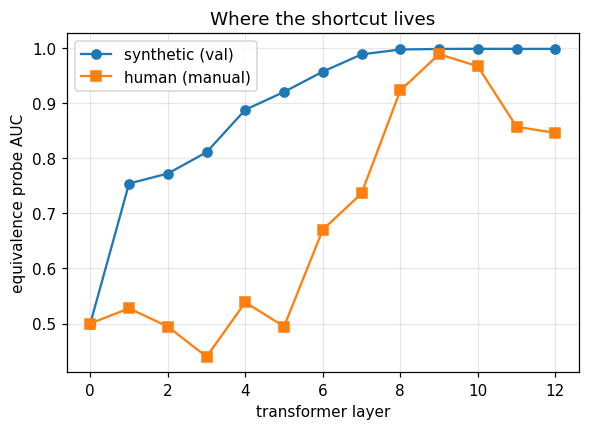

In [5]:
# Per-layer probe AUC, synthetic (val) vs human (manual), from the saved metrics.
import json
import matplotlib.pyplot as plt

pm = json.load(open("results/probe_metrics.json"))["metrics_by_layer"]
layers = [m["layer"] for m in pm]
val    = [m["probe_equiv_auc_val"]    for m in pm]
human  = [m["probe_equiv_auc_manual"] for m in pm]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(layers, val,   "o-", label="synthetic (val)")
ax.plot(layers, human, "s-", label="human (manual)")
ax.set_xlabel("transformer layer")
ax.set_ylabel("equivalence probe AUC")
ax.set_title("Where the shortcut lives")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

### 9.2 Directional ablation: finding  ~~Waldo~~ shortcuts

If the shortcut were a single direction in activation space, projecting that direction out of the `<s>` vector would kill it. And then we could continue and our model would work! We try this at layer 12, and try, and try, multiple methods, by removing up to six hand-picked stylistic directions (negation flip, length ratio, "the post" prefix, first-person, much-shorter, verdict word).

| Directions removed (cumulative) | Human-eval AUC |
|---|---|
| 0 (none) | 0.769 |
| plus negation flip | 0.791 |
| plus length ratio | 0.769 |
| plus "the post" prefix | 0.780 |
| plus first-person | 0.758 |
| plus much-shorter | 0.769 |
| plus verdict word | 0.758 |

Removing all six directions changes the AUC by 0.011, which is basically nothing. Therefore the shortcut is not stored in one direction but is spread across many of them. This is backed by literature: the amnesic-probing work of Elazar et al. (2021) shows that a property (in this case, the shortcut) across many directions cannot be cleanly removed at inference. 

We somehow have to stop the shortcut from forming during training, instead of trying to erase it afterwards.

In [ ]:
import numpy as np


def project_out(X, directions):
    """Remove a set of directions from every row of X.

    Used to test whether the shortcut sits in a few dimensions. If removing the
    top label-aligned directions does not lower the probe AUC, the feature is
    spread across many directions.
    """
    X = X.copy()
    for d in directions:
        d = d / (np.linalg.norm(d) + 1e-8)
        X = X - np.outer(X @ d, d)
    return X

The function above is the directional-ablation method. The actual layer-12 result, that removing the six most label-aligned directions barely moves the AUC, is the figure in Appendix A, rebuilt from `results/overnight/stage6_baseline_layer12.json`.

## 10. The fix: training on many generators

If the shortcut is one generator's style, then the fix is to use many generators. It seems obvious but it took us a while to figure out...

 We regenerate the pairs from the same 100 held-out, out-of-domain source posts using five instruction-tuned LLMs (Claude Haiku 4.5, GPT-4o-mini, Qwen2.5-72B, Llama 3.1 8B, and DeepSeek V3), at 200 pairs each (100 equivalent and 100 non-equivalent), for about 1,000 pairs in total. Then we fine-tune a fresh RoBERTa on the combined set.  

Here are the results across human-written and cross-LLM rationales:

| Training recipe | Handwritten (n=20) | Claude 4.6 (n=20) | GPT-4o-mini (n=50) | Claude Haiku (n=100) |
|---|---|---|---|---|
| Single-generator | 55% | 65% | 54% | 59% |
| Multi-generator | 95% | 85% | 72% | 81% |
| Drop Claude Haiku | 60% | 55% | 42% | 60% |
| Drop DeepSeek | 95% | 85% | 76% | 80% |

Two things come out of this.

Diversity actually beats scale. About 1,000 diverse pairs is enough data to remove the collapse, while 52,000 single-generator pairs did not. And in a leave-one-out test at a fixed budget of about 800 pairs, which generators you keep swings the accuracy from 60% (drop Claude Haiku) up to 95% (drop DeepSeek).  

The generators are not interchangeable. Claude Haiku carries a lot of the accuracythat nothing else provides, so dropping it hurts a lot. DeepSeek is redundant. Dropping it doesn't change anything. 

The next two cells are excerpts of the cluster and API scripts in `code/generator_diversity/`: the first calls each generator through OpenRouter, the second trains one judge per generator. They need API keys and a GPU queue, so they are shown for reference and do not run inside the notebook. You can run them through there if you are curious, or you can use the dataset we already created in `results/cross_gen/`

The full matrix can be found in Appendix Table III.

In [ ]:
# One source post -> two paraphrases (equivalent, unequivalent) per generator,
# using the same two system prompts from Section 2, sent to each model through
# OpenRouter. 

# This is an excerpt of the code and will not run! 
# Needs API key. 
# Full code can be found in code/generator_diversity/
GENERATORS = {
    "anthropic_haiku":  "anthropic/claude-haiku-4.5",
    "openai_gpt4omini": "openai/gpt-4o-mini",
    "qwen25_72b":       "qwen/qwen-2.5-72b-instruct",
    "meta_llama3_8b":   "meta-llama/llama-3.1-8b-instruct",
    "deepseek_v3":      "deepseek/deepseek-chat-v3.1",
}


def generate_pairs(model, posts):
    rows = []
    for _, row in posts.iterrows():
        for label in ("equivalent", "unequivalent"):
            system = (SYSTEM_PROMPT_EQUIVALENT if label == "equivalent"
                      else SYSTEM_PROMPT_UNEQUIVALENT)
            text = call_openrouter(model, system, row["explanation"])
            rows.append({"text_a": row["explanation"], "text_b": text,
                         "meaning": label, "post_id": row["uid"],
                         "domain": row["domain"]})
    return pd.DataFrame(rows)

In [ ]:
# Train one judge per generator, plus a multi-generator judge on the union of
# all five training splits (about 800 pairs).  

# This is an excerpt of the code and will not run! 
# Needs API key. 
# Full code can be found in code/generator_diversity/
union = pd.concat([train_dfs[g] for g in GENERATORS], ignore_index=True)
multi_gen = train_classifier(union, name="multi_gen", epochs=3)

# Drop each generator in turn, train on the remaining four, evaluate on the
# handwritten set 
for held_out in GENERATORS:
    union = pd.concat([train_dfs[g] for g in GENERATORS if g != held_out],
                      ignore_index=True)
    ckpt = train_classifier(union, name=f"drop_{held_out}", epochs=3)
    acc = evaluate(ckpt, handwritten_set)
    print(f"drop {held_out:18s} -> handwritten acc {acc:.2f}")

In [ ]:
# Rebuild the multi-generator union from the committed cross-gen CSVs  

import glob, os, pandas as pd

VALID, total = {"equivalent", "unequivalent"}, 0
for f in sorted(glob.glob("results/cross_gen/*.csv")):
    slug = os.path.basename(f)[:-4]
    if slug.startswith("_"):
        continue
    if os.path.getsize(f) == 0:
        print(f"{slug:18} 0 rows (failed)")
        continue
    d = pd.read_csv(f).dropna(subset=["explanation", "synthetic", "meaning"])
    d = d[d.meaning.isin(VALID)]
    print(f"{slug:18} {len(d)} usable")
    total += len(d)
print("-" * 32)
print(f"multi_gen union  : {total} pairs (about 1,000)")

anthropic_haiku    200 usable
deepseek_v3        200 usable
meta_llama3_8b     200 usable
mistral_7b         0 usable
openai_gpt4omini   200 usable
qwen25_72b         198 usable
--------------------------------
multi_gen union  : 998 pairs (about 1,000)


## 11. What we take away / Conclusion

A small encoder trained on single-generator synthetic data gives you a semantic illusion. The validation scores look great, but they hide a stylistic shortcut that breaks on any rationale written by a different hand.

The interpretability work puts the shortcut in the deep layers and shows it is spread across many directions, so you cannot ablate it away at inference. It has to be prevented while training.

Generator diversity is that prevention. About 1,000 cross-generator pairs reach 72 to 95% on human and synthetic data and recover roughly 80% of a frontier model's judging accuracy at a fraction of the cost, which clearly beats just piling on more data from one generator.

The honest limit is the task itself. Forcing subjective human judgements about hate speech into a strict binary equivalent or unequivalent label caps how well any judge can really do.

---
## Appendix A: Reproducing the numbers from the stored artifacts

Everything above was run on the cluster, but the results are committed to the repo as JSON and CSV. The cells below load those artifacts and rebuild the report's tables and figures, so the whole thing can be checked from a clean clone. Each cell is self-contained and all paths are relative to the repo root. 


In [7]:
# Table II: judge performance (F1) on the held-out domains.
# Self-contained: GPT-4o-mini and RoBERTa come from the saved verification run,
# and the TF-IDF baseline is recomputed here so the table needs no other cell.
import json
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

r = json.load(open("results/verify_poster_results.json"))

# Recompute the TF-IDF + LogReg baseline on the domain-OOD split (its per-domain
# numbers are not stored in the JSON).
L2I, TEST = {"equivalent": 0, "unequivalent": 1}, {"toxigen", "gab", "anatomy"}
df = pd.read_csv("data/reformulated_full.csv").dropna(
    subset=["explanation", "synthetic", "meaning", "domain"])
df = df[df.meaning.isin(L2I)].copy()
df["y"] = df.meaning.map(L2I)
tr, te = df[~df.domain.isin(TEST)], df[df.domain.isin(TEST)]
vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2))
clf = LogisticRegression(max_iter=1000).fit(
    vec.fit_transform(tr.explanation + " [SEP] " + tr.synthetic), tr.y)
pred = clf.predict(vec.transform(te.explanation + " [SEP] " + te.synthetic))
tfidf = {"overall": f1_score(te.y, pred, average="macro")}
for dom in ["anatomy", "gab", "toxigen"]:
    m = (te.domain == dom).values
    tfidf[dom] = f1_score(te.y[m], pred[m], average="macro")

# Assemble the table.
t2 = pd.DataFrame(index=["TF-IDF + LogReg", "GPT-4o-mini zero-shot", "RoBERTa (ours)"])
t2["Overall F1"] = [round(tfidf["overall"], 3),
                    round(r["gpt4omini"]["f1_macro"], 3),
                    round(r["roberta_ood"]["f1_macro"], 3)]
for dom in ["anatomy", "gab", "toxigen"]:
    t2.loc["TF-IDF + LogReg", dom.capitalize()] = round(tfidf[dom], 3)
for label, key in [("GPT-4o-mini zero-shot", "gpt4omini"), ("RoBERTa (ours)", "roberta_ood")]:
    for dom in ["anatomy", "gab", "toxigen"]:
        t2.loc[label, dom.capitalize()] = round(r[key]["per_domain"][dom]["f1_macro"], 3)
t2

,Overall F1,Anatomy,Gab,Toxigen
TF-IDF + LogReg,0.789,0.750,0.779,0.821
GPT-4o-mini zero-shot,0.964,0.914,0.994,0.979
RoBERTa (ours),0.968,0.949,0.976,0.977


In [2]:
# Cosine similarity of the pairs. Non-equivalent pairs sit at a higher median
# similarity than equivalent ones, which is the shortcut in one number.
c = r["cosine"]
pd.DataFrame({
    "mean":   [c["equivalent"]["mean"],       c["unequivalent"]["mean"]],
    "median": [c["equivalent"]["median"],     c["unequivalent"]["median"]],
    ">0.9 %": [c["equivalent"]["pct_gt_0_9"], c["unequivalent"]["pct_gt_0_9"]],
}, index=["equivalent", "non-equivalent"]).round(3)

,mean,median,>0.9 %
equivalent,0.746,0.762,21.597
non-equivalent,0.784,0.904,50.867


In [3]:
# The off-distribution collapse and the negation shortcut.
o  = json.load(open("results/verify_ood_results.json"))
ng = json.load(open("results/verify_negation_prior_results.json"))
print("OOD accuracy, human-written  (n=20):", o["manual"]["accuracy"])
print("OOD accuracy, Claude-written (n=20):", o["claude"]["accuracy"])
print("negation regex predicts label, AUC :", round(ng["regex_auc_vs_label"], 3))

OOD accuracy, human-written  (n=20): 0.55
OOD accuracy, Claude-written (n=20): 0.65
negation regex predicts label, AUC : 0.72


change from K=0 to K=6: 0.011


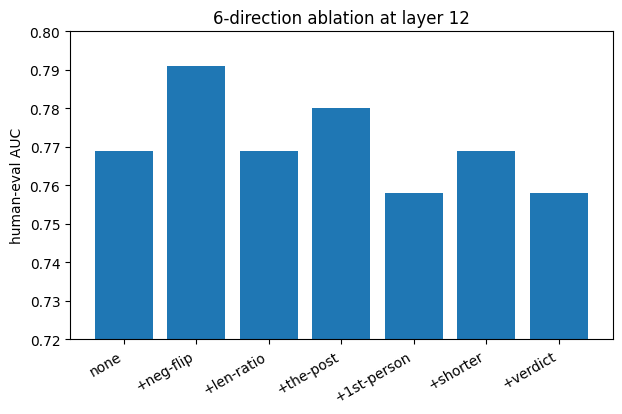

In [4]:
# Directional ablation at layer 12. Removing six stylistic directions barely
# moves the human-eval AUC, so the shortcut is redundantly encoded.
import matplotlib.pyplot as plt

ab = json.load(open("results/overnight/stage6_baseline_layer12.json"))["sweep"]
auc = [round(s["eq_manual"], 3) for s in ab]
labels = ["none", "+neg-flip", "+len-ratio", "+the-post", "+1st-person", "+shorter", "+verdict"]
print("change from K=0 to K=6:", round(ab[0]["eq_manual"] - ab[-1]["eq_manual"], 3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(auc)), auc)
ax.set_xticks(range(len(auc))); ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_ylim(0.72, 0.80); ax.set_ylabel("human-eval AUC")
ax.set_title("6-direction ablation at layer 12")
plt.show()

In [5]:
# Table III: rebuild the full recipe matrix from the stage14 and stage14b runs.
m14b = json.load(open("results/overnight/stage14b_matrix.json"))
m14  = json.load(open("results/overnight/stage14_matrix.json"))

recipes = [("Single-Gen", "poster_baseline"), ("Multi-Gen", "multi_gen"),
           ("Drop Haiku", "loo_drop_anthropic"), ("Drop DeepSeek", "loo_drop_deepseek")]
pct = lambda x: f"{x:.0%}"
pd.DataFrame([{
    
    "Training Recipe": name,
    "Handwritten (n=20)":   pct(m14b[key]["manual_handwritten_n20"]["acc"]),
    "Claude 4.6 (n=20)":    pct(m14b[key]["claude46_n20"]["acc"]),
    "GPT-4o-mini (n=50)":   pct(m14[key]["stage7_gpt_n50"]["acc"]),
    "Claude Haiku (n=100)": pct(m14[key]["stage10_haiku_n100"]["acc"]),
} for name, key in recipes])

,Training Recipe,Handwritten (n=20),Claude 4.6 (n=20),GPT-4o-mini (n=50),Claude Haiku (n=100)
0,Single-Gen,55%,65%,54%,59%
1,Multi-Gen,95%,85%,72%,81%
2,Drop Haiku,60%,55%,42%,60%
3,Drop DeepSeek,95%,85%,76%,80%
